# USCityURL Orlando Resilience EDA Demo

This notebook shows how the pipeline starts with a city name and finds its official website. It then collects a small set of resilience-related pages and checks what useful text they contain.

## Demo workflow

The demo follows the same path from city lookup to a small document analysis. Each step keeps the search limited and records what was found so the results can be checked later.

1. Load USCityURL and select Orlando.
2. Crawl a limited number of pages on the official Orlando website.
3. Filter links using resilience-related keywords.
4. Extract and clean text from a small sample.
5. Check extraction quality and perform preliminary EDA.

## 1. Set up the demo

This section loads the tools used to read websites, PDFs, tables, and charts. It also sets small crawl limits so the demo stays quick and does not scan the entire city website.

In [16]:
import io
import re
import time
from urllib.parse import urldefrag, urljoin, urlsplit, urlunsplit

import pymupdf
import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display

USCITYURL_CSV = "datasets_USCityPipeline/USCityURL_Pipeline.csv"
MAX_PAGES_TO_CRAWL = 60
MAX_DOCUMENTS_TO_ANALYZE = 15
REQUEST_TIMEOUT = 15
REQUEST_DELAY = 0.15

HEADERS = {
    "User-Agent": "CMSE495-USCityURL-Demo/1.0 (educational research)"
}
session = requests.Session()
session.headers.update(HEADERS)

plt.style.use("seaborn-v0_8-whitegrid")
print("Demo limits:", MAX_PAGES_TO_CRAWL, "crawl pages and", MAX_DOCUMENTS_TO_ANALYZE, "documents")

Demo limits: 60 crawl pages and 15 documents


## 2. Find Orlando's verified official website

The pipeline-ready USCityURL file contains only municipalities whose audited homepage returned successful HTML. The code selects the single Orlando, Florida record before any pages are collected.

In [17]:
cities = pd.read_csv(USCITYURL_CSV)

required_columns = {"MUNICIPALITY", "STATE", "WEBSITE_URL"}
missing_columns = required_columns.difference(cities.columns)
if missing_columns:
    raise ValueError(f"USCityURL is missing required columns: {sorted(missing_columns)}")

orlando_rows = cities.loc[
    cities["MUNICIPALITY"].astype(str).str.strip().str.casefold().eq("orlando")
    & cities["STATE"].astype(str).str.strip().str.casefold().eq("florida")
]

if len(orlando_rows) != 1:
    raise ValueError(f"Expected one Orlando, Florida row; found {len(orlando_rows)}")

base_url = orlando_rows.iloc[0]["WEBSITE_URL"]
official_host = urlsplit(base_url).netloc.lower()

print("USCityURL records:", f"{len(cities):,}")
print("Selected city: Orlando, Florida")
print("Official website:", base_url)

USCityURL records: 11,608
Selected city: Orlando, Florida
Official website: https://www.orlando.gov/Home


## 3. Find possible resilience documents

The crawler follows links only on Orlando's official website and stops after a fixed number of pages. It keeps links containing resilience-related words, then ranks likely plans above more general pages.

In [18]:
RESILIENCE_KEYWORDS = [
    "resilience", "resiliency", "hazard", "mitigation", "climate",
    "adaptation", "emergency", "flood", "hurricane", "storm",
    "sustainability", "future ready", "comprehensive plan", "master plan",
]
SKIP_EXTENSIONS = (".jpg", ".jpeg", ".png", ".gif", ".svg", ".zip", ".mp4", ".mp3")
SKIP_HOSTS = {"facebook.com", "www.facebook.com", "twitter.com", "x.com", "maps.google.com"}

def normalize_url(url):
    """Return a stable URL without fragments or tracking/language queries."""
    clean_url, _ = urldefrag(str(url))
    parts = urlsplit(clean_url)
    path = parts.path or "/"
    return urlunsplit((parts.scheme.lower(), parts.netloc.lower(), path, "", ""))

def fetch(url):
    """Request one public page and return the response or an error message."""
    try:
        response = session.get(url, timeout=REQUEST_TIMEOUT, allow_redirects=True)
        response.raise_for_status()
        return response, None
    except requests.RequestException as error:
        return None, f"{type(error).__name__}: {error}"

def page_links(page_url, html):
    """Collect usable links and their visible anchor text from one HTML page."""
    soup = BeautifulSoup(html, "html.parser")
    found = []
    for anchor in soup.find_all("a", href=True):
        raw_url = anchor["href"].strip()
        if raw_url.startswith(("mailto:", "tel:", "javascript:")):
            continue
        full_url = normalize_url(urljoin(page_url, raw_url))
        parts = urlsplit(full_url)
        if parts.netloc in SKIP_HOSTS or parts.path.lower().endswith(SKIP_EXTENSIONS):
            continue
        found.append({"anchor_text": anchor.get_text(" ", strip=True), "url": full_url})
    return found

to_visit = [normalize_url(base_url)]
visited = set()
collected_links = []
crawl_failures = []

while to_visit and len(visited) < MAX_PAGES_TO_CRAWL:
    current_url = to_visit.pop(0)
    if current_url in visited:
        continue
    visited.add(current_url)

    response, error = fetch(current_url)
    if error:
        crawl_failures.append({"url": current_url, "error": error})
        continue

    links = page_links(response.url, response.text)
    collected_links.extend(links)
    for item in links:
        link_host = urlsplit(item["url"]).netloc.lower()
        if link_host == official_host and item["url"] not in visited and item["url"] not in to_visit:
            to_visit.append(item["url"])
    time.sleep(REQUEST_DELAY)

links_df = pd.DataFrame(collected_links).drop_duplicates(subset="url")
links_df = links_df.loc[
    links_df["url"].apply(lambda url: urlsplit(url).netloc.lower() == official_host)
].copy()
links_df["search_text"] = (links_df["anchor_text"].fillna("") + " " + links_df["url"]).str.casefold()
links_df["keywords_found"] = links_df["search_text"].apply(
    lambda text: [keyword for keyword in RESILIENCE_KEYWORDS if keyword in text]
)
relevant_links = links_df.loc[links_df["keywords_found"].str.len() > 0].copy()
planning_phrases = ["resilience plan", "comprehensive plan", "hazard mitigation", "climate action"]
relevant_links["relevance_score"] = relevant_links.apply(
    lambda row: len(row["keywords_found"])
    + 3 * sum(phrase in row["search_text"] for phrase in planning_phrases),
    axis=1,
)
relevant_links = relevant_links.sort_values(
    ["relevance_score", "anchor_text"], ascending=[False, True]
).reset_index(drop=True)

print("Pages visited:", len(visited))
print("Unique links collected:", f"{len(links_df):,}")
print("Candidate resilience links:", len(relevant_links))
print("Crawl failures:", len(crawl_failures))
display(relevant_links[["anchor_text", "url", "keywords_found"]].head(10))

Pages visited: 60
Unique links collected: 736
Candidate resilience links: 20
Crawl failures: 2


,anchor_text,url,keywords_found
0,Orlando Resilience Plan,https://www.orlando.gov/Our-Government/Orlando...,[resilience]
1,"Volunteer with the Office of Sustainability, R...",https://www.orlando.gov/Community-Programs-Eve...,"[resilience, sustainability, future ready]"
2,Apply for a Flood Permit Do you want to build ...,https://www.orlando.gov/Building-Development/P...,"[hazard, flood]"
3,Apply for a Tree Removal or Encroachment Permi...,https://www.orlando.gov/Building-Development/P...,[hazard]
4,Become a Police Department Emergency Communica...,https://www.orlando.gov/Public-Safety/OPD/Beco...,[emergency]
5,Become an Orlando Fire Department Emergency Co...,https://www.orlando.gov/Public-Safety/OFD/Beco...,[emergency]
6,Community Development Block Grants & Emergency...,https://www.orlando.gov/Building-Development/H...,[emergency]
7,Emergency Operation Center,https://www.orlando.gov/Our-Government/Departm...,[emergency]
8,Find out if you live in a Floodplain,https://www.orlando.gov/Parks-the-Environment/...,[flood]
9,Floodplain Management Plan Study,https://www.orlando.gov/Building-Development/C...,[flood]


## 4. Extract and check a small document sample

The highest-ranked HTML pages and PDFs are converted into plain text. Short, failed, and exactly duplicated results are labeled so only usable unique documents move into the analysis.

In [19]:
def clean_text(text):
    return re.sub(r"\s+", " ", text or "").strip()

def extract_document(row):
    response, error = fetch(row["url"])
    result = {
        "title": row["anchor_text"] or row["url"],
        "url": row["url"],
        "keywords_found": row["keywords_found"],
        "status": "failed" if error else "ok",
        "http_status": None if response is None else response.status_code,
        "format": "unknown",
        "extraction_method": "none",
        "error": error,
        "text": "",
    }
    if response is None:
        return result

    content_type = response.headers.get("Content-Type", "").lower()
    is_pdf = "pdf" in content_type or response.content.startswith(b"%PDF")
    try:
        if is_pdf:
            with pymupdf.open(stream=io.BytesIO(response.content), filetype="pdf") as pdf:
                text = " ".join(page.get_text("text") for page in pdf)
            result["format"] = "PDF"
            result["extraction_method"] = "PyMuPDF"
        else:
            soup = BeautifulSoup(response.text, "html.parser")
            for tag in soup(["script", "style", "nav", "header", "footer"]):
                tag.decompose()
            main_content = soup.find("main") or soup.find("article") or soup.body or soup
            text = main_content.get_text(" ", strip=True)
            result["format"] = "HTML"
            result["extraction_method"] = "BeautifulSoup"
        result["text"] = clean_text(text)
    except Exception as extraction_error:
        result["status"] = "failed"
        result["error"] = f"{type(extraction_error).__name__}: {extraction_error}"
    return result

sample_links = relevant_links.head(MAX_DOCUMENTS_TO_ANALYZE)
documents = pd.DataFrame([extract_document(row) for _, row in sample_links.iterrows()])
documents["word_count"] = documents["text"].str.findall(r"\b[\w'-]+\b").str.len()
documents["quality"] = documents["word_count"].apply(
    lambda count: "Failed" if count == 0 else ("Short - review" if count < 100 else "Usable")
)
documents["normalized_text"] = documents["text"].str.casefold().str.replace(r"\s+", " ", regex=True)
documents["exact_duplicate"] = documents["normalized_text"].duplicated(keep="first")

analysis_df = documents.loc[
    documents["quality"].eq("Usable") & ~documents["exact_duplicate"]
].copy()

display(documents[["title", "format", "word_count", "quality", "exact_duplicate"]])
print("Usable unique documents for EDA:", len(analysis_df))

,title,format,word_count,quality,exact_duplicate
0,Orlando Resilience Plan,HTML,627,Usable,False
1,"Volunteer with the Office of Sustainability, R...",HTML,0,Failed,False
2,Apply for a Flood Permit Do you want to build ...,HTML,345,Usable,False
3,Apply for a Tree Removal or Encroachment Permi...,HTML,446,Usable,False
4,Become a Police Department Emergency Communica...,HTML,780,Usable,False
5,Become an Orlando Fire Department Emergency Co...,HTML,729,Usable,False
6,Community Development Block Grants & Emergency...,HTML,820,Usable,False
7,Emergency Operation Center,HTML,22,Short - review,False
8,Find out if you live in a Floodplain,HTML,528,Usable,False
9,Floodplain Management Plan Study,HTML,660,Usable,False


Usable unique documents for EDA: 12


## 5. Explore the collected text

The first chart counts common resilience topics across the full sample. The second compares documents using mentions per 1,000 words, which makes documents of different lengths easier to compare.

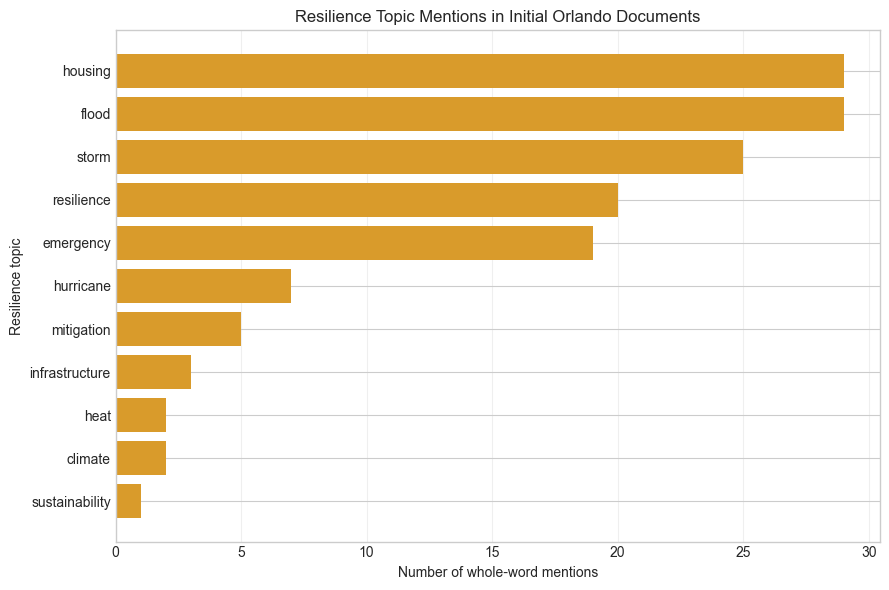

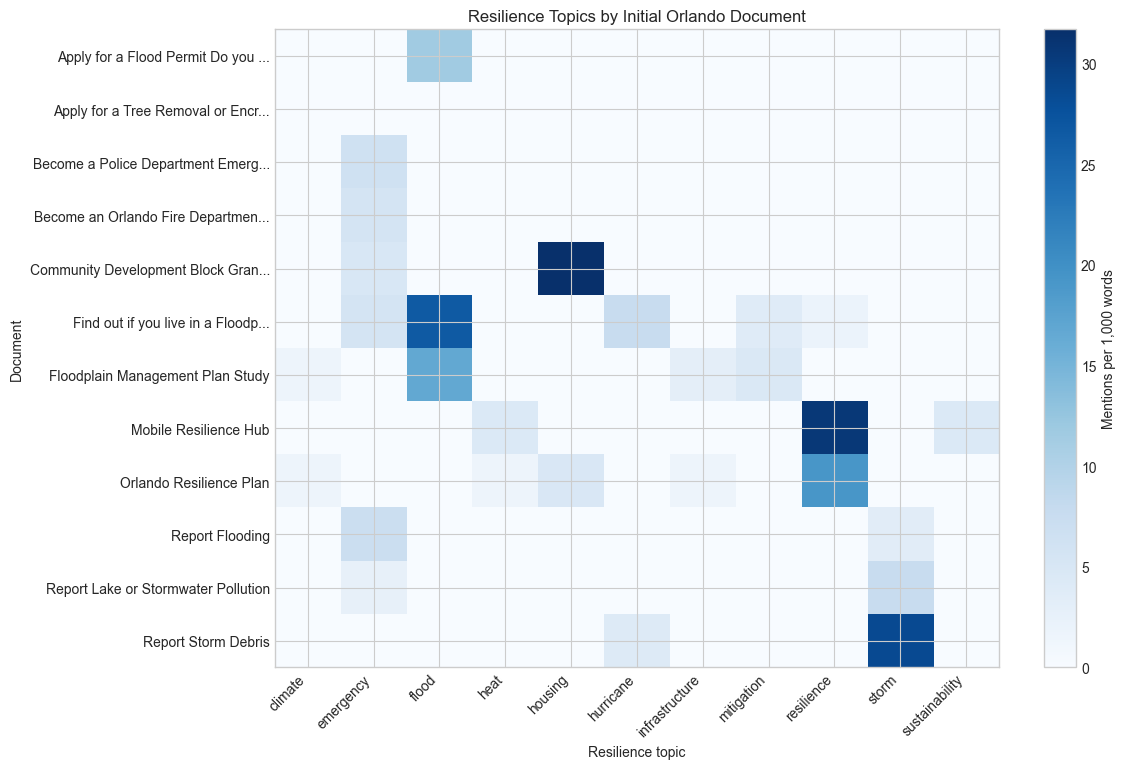

,topic,mentions
0,flood,29
1,housing,29
2,storm,25
3,resilience,20
4,emergency,19
5,hurricane,7
6,mitigation,5
7,infrastructure,3
8,climate,2
9,heat,2


In [20]:
if analysis_df.empty:
    raise RuntimeError("No usable documents were extracted. Review the candidate and failure tables above.")

TOPICS = [
    "resilience", "climate", "flood", "hurricane", "storm",
    "heat", "housing", "infrastructure", "emergency", "mitigation", "sustainability",
]

def count_topic(text, topic):
    pattern = rf"(?<!\w){re.escape(topic)}(?!\w)"
    return len(re.findall(pattern, text or "", flags=re.IGNORECASE))


# Plot 1: total resilience-topic mentions
topic_counts = {
    topic: sum(count_topic(text, topic) for text in analysis_df["text"])
    for topic in TOPICS
}
topic_df = pd.DataFrame(
    topic_counts.items(), columns=["topic", "mentions"]
).sort_values("mentions", ascending=False)
topic_plot = topic_df.sort_values("mentions")

plt.figure(figsize=(9, 6))
plt.barh(topic_plot["topic"], topic_plot["mentions"], color="#d99b2b")
plt.title("Resilience Topic Mentions in Initial Orlando Documents")
plt.xlabel("Number of whole-word mentions")
plt.ylabel("Resilience topic")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 2: topic mentions per 1,000 words in each document
topic_rows = []
for _, document in analysis_df.iterrows():
    for topic in TOPICS:
        mentions = count_topic(document["text"], topic)
        topic_rows.append({
            "document": document["title"],
            "topic": topic,
            "mentions_per_1000_words": mentions / document["word_count"] * 1000,
        })

document_topics = pd.DataFrame(topic_rows)
topic_matrix = document_topics.pivot(
    index="document",
    columns="topic",
    values="mentions_per_1000_words",
).fillna(0)
short_document_names = [
    title if len(title) <= 35 else title[:32] + "..."
    for title in topic_matrix.index
]

fig, ax = plt.subplots(figsize=(12, max(5, len(topic_matrix) * 0.65)))
heatmap = ax.imshow(topic_matrix.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(topic_matrix.columns)))
ax.set_xticklabels(topic_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(topic_matrix.index)))
ax.set_yticklabels(short_document_names)
ax.set_title("Resilience Topics by Initial Orlando Document")
ax.set_xlabel("Resilience topic")
ax.set_ylabel("Document")
colorbar = plt.colorbar(heatmap, ax=ax)
colorbar.set_label("Mentions per 1,000 words")
plt.tight_layout()
plt.show()

display(topic_df.reset_index(drop=True))

## 6. Summarize the demo run

The final check prints how many pages, candidate links, and usable documents moved through the pipeline. These counts are an audit trail for this run and may change when the live website changes.

In [21]:
print("Pipeline complete")
print("- Orlando selected from USCityURL:", base_url)
print("- Pages visited:", len(visited))
print("- Candidate links found:", len(relevant_links))
print("- Documents sampled:", len(documents))
print("- Usable unique documents analyzed:", len(analysis_df))
print("- Most mentioned sample topic:", topic_df.iloc[0]["topic"], f"({topic_df.iloc[0]['mentions']} mentions)")

Pipeline complete
- Orlando selected from USCityURL: https://www.orlando.gov/Home
- Pages visited: 60
- Candidate links found: 20
- Documents sampled: 15
- Usable unique documents analyzed: 12
- Most mentioned sample topic: flood (29 mentions)


# 7. Additional multi-city comparison

This section uses the new pipeline-ready dataset, then independently runs the original multi-city collection rules for each available city.

### How this differs from the Orlando pipeline above

- Both use limits of 60 pages, 15 documents, a 15-second timeout, and a 0.15-second delay.
- The comparison verifies HTML before collecting links, rejects non-HTTP links, and treats non-HTML, non-PDF files as unsupported.
- It also waits between document extractions and records the city, state, and collection time; the Orlando code above only waits between crawled pages.
- The resilience keywords, relevance scoring, 100-word quality cutoff, and exact-duplicate rule remain the same.

## 7.1 Collect comparable city results

The pipeline records the same crawl, document, duplicate, word, and failure counts for each city. A zero can reflect an access or extraction failure and should not be read as proof that a city has no resilience work.

In [22]:
from collections import deque
from datetime import datetime, timezone

COMPARISON_SOURCE_CSV = USCITYURL_CSV
COMPARISON_MAX_PAGES = 60
COMPARISON_MAX_DOCUMENTS = 15
COMPARISON_TIMEOUT = 15
COMPARISON_DELAY = 0.15

COMPARISON_CITIES = [
    ("Orlando", "Florida"),
    ("Miami", "Florida"),
    ("Seattle", "Washington"),
]

COMPARISON_KEYWORDS = [
    "resilience", "resiliency", "hazard", "mitigation",
    "climate", "adaptation", "emergency", "flood",
    "hurricane", "storm", "sustainability",
    "future ready", "comprehensive plan", "master plan",
]
COMPARISON_PLANNING_PHRASES = [
    "resilience plan", "comprehensive plan",
    "hazard mitigation", "climate action",
]
COMPARISON_SKIP_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".gif",
    ".svg", ".zip", ".mp4", ".mp3",
)
COMPARISON_SKIP_HOSTS = {
    "facebook.com", "www.facebook.com",
    "twitter.com", "x.com", "maps.google.com",
}

comparison_session = requests.Session()
comparison_session.headers.update({
    "User-Agent": "CMSE495-USCityURL-Demo/1.0 (educational research)"
})


def comparison_normalize_url(url):
    clean_url, _ = urldefrag(str(url))
    parts = urlsplit(clean_url)
    return urlunsplit((
        parts.scheme.lower(), parts.netloc.lower(), parts.path or "/", "", ""
    ))


def comparison_fetch(url):
    try:
        response = comparison_session.get(
            url, timeout=COMPARISON_TIMEOUT, allow_redirects=True
        )
        response.raise_for_status()
        return response, None
    except requests.RequestException as error:
        return None, f"{type(error).__name__}: {error}"


def comparison_page_links(page_url, html):
    soup = BeautifulSoup(html, "html.parser")
    found = []
    for anchor in soup.find_all("a", href=True):
        raw_url = anchor["href"].strip()
        if raw_url.startswith(("mailto:", "tel:", "javascript:")):
            continue
        full_url = comparison_normalize_url(urljoin(page_url, raw_url))
        parts = urlsplit(full_url)
        if parts.scheme not in ("http", "https"):
            continue
        if parts.netloc in COMPARISON_SKIP_HOSTS:
            continue
        if parts.path.lower().endswith(COMPARISON_SKIP_EXTENSIONS):
            continue
        found.append({
            "anchor_text": anchor.get_text(" ", strip=True),
            "url": full_url,
        })
    return found


def comparison_extract_document(row):
    response, error = comparison_fetch(row["url"])
    result = {
        "title": row["anchor_text"] or row["url"],
        "url": row["url"],
        "keywords_found": row["keywords_found"],
        "status": "failed" if error else "ok",
        "format": "unknown",
        "extraction_method": "none",
        "error": error,
        "text": "",
    }
    if response is None:
        return result

    content_type = response.headers.get("Content-Type", "").lower()
    is_pdf = "pdf" in content_type or response.content.startswith(b"%PDF")
    try:
        if is_pdf:
            with pymupdf.open(stream=io.BytesIO(response.content), filetype="pdf") as pdf:
                text = " ".join(page.get_text("text") for page in pdf)
            result["format"] = "PDF"
            result["extraction_method"] = "PyMuPDF"
        elif "html" in content_type:
            soup = BeautifulSoup(response.text, "html.parser")
            for tag in soup(["script", "style", "nav", "header", "footer"]):
                tag.decompose()
            main = soup.find("main") or soup.find("article") or soup.body or soup
            text = main.get_text(" ", strip=True)
            result["format"] = "HTML"
            result["extraction_method"] = "BeautifulSoup"
        else:
            result["status"] = "unsupported"
            result["error"] = content_type
            return result
        result["text"] = clean_text(text)
    except Exception as error:
        result["status"] = "failed"
        result["error"] = str(error)
    return result


def collect_city_results(city, state, city_url):
    """Run the original multi-city crawl and extraction rules for one city."""
    official_host = urlsplit(city_url).netloc.lower()
    to_visit = deque([comparison_normalize_url(city_url)])
    city_visited = set()
    city_links = []
    city_failures = []

    while to_visit and len(city_visited) < COMPARISON_MAX_PAGES:
        current_url = to_visit.popleft()
        if current_url in city_visited:
            continue
        city_visited.add(current_url)

        response, error = comparison_fetch(current_url)
        if error:
            city_failures.append({"municipality": city, "url": current_url, "error": error})
            continue

        content_type = response.headers.get("Content-Type", "").lower()
        if "html" not in content_type:
            continue

        found_links = comparison_page_links(response.url, response.text)
        city_links.extend(found_links)
        for item in found_links:
            link_host = urlsplit(item["url"]).netloc.lower()
            if link_host == official_host and item["url"] not in city_visited and item["url"] not in to_visit:
                to_visit.append(item["url"])
        time.sleep(COMPARISON_DELAY)

    links = pd.DataFrame(city_links, columns=["anchor_text", "url"]).drop_duplicates("url")
    if not links.empty:
        links = links.loc[
            links["url"].apply(lambda url: urlsplit(url).netloc.lower() == official_host)
        ].copy()

    if links.empty:
        candidates = pd.DataFrame(columns=[
            "anchor_text", "url", "search_text", "keywords_found", "relevance_score"
        ])
    else:
        links["search_text"] = (
            links["anchor_text"].fillna("") + " " + links["url"]
        ).str.casefold()
        links["keywords_found"] = links["search_text"].apply(
            lambda text: [keyword for keyword in COMPARISON_KEYWORDS if keyword in text]
        )
        candidates = links.loc[links["keywords_found"].str.len() > 0].copy()
        candidates["relevance_score"] = candidates.apply(
            lambda row: len(row["keywords_found"])
            + 3 * sum(phrase in row["search_text"] for phrase in COMPARISON_PLANNING_PHRASES),
            axis=1,
        )
        candidates = candidates.sort_values(
            ["relevance_score", "anchor_text"], ascending=[False, True]
        ).reset_index(drop=True)

    extracted = []
    for _, row in candidates.head(COMPARISON_MAX_DOCUMENTS).iterrows():
        document = comparison_extract_document(row)
        document["municipality"] = city
        document["state"] = state
        document["collection_date"] = datetime.now(timezone.utc).isoformat()
        document["word_count"] = len(re.findall(r"\b[\w'-]+\b", document["text"]))
        document["quality"] = (
            "Failed" if document["word_count"] == 0
            else "Short - review" if document["word_count"] < 100
            else "Usable"
        )
        extracted.append(document)
        time.sleep(COMPARISON_DELAY)

    city_documents = pd.DataFrame(extracted)

    if city_documents.empty:
        usable = pd.DataFrame()
        duplicate_count = 0
        total_words = 0
    else:
        city_documents["normalized_text"] = (
            city_documents["text"].str.casefold().str.replace(r"\s+", " ", regex=True)
        )
        city_documents["exact_duplicate"] = city_documents["normalized_text"].duplicated(keep="first")
        usable = city_documents.loc[
            city_documents["quality"].eq("Usable") & ~city_documents["exact_duplicate"]
        ].copy()
        duplicate_count = int(city_documents["exact_duplicate"].sum())
        total_words = int(usable["word_count"].sum())

    summary = {
        "Municipality": city,
        "State": state,
        "Pages_Visited": len(city_visited),
        "Unique_Links": len(links),
        "Candidate_Links": len(candidates),
        "Documents_Attempted": len(city_documents),
        "Usable_Documents": len(usable),
        "Exact_Duplicates": duplicate_count,
        "Total_Usable_Words": total_words,
        "Crawl_Failures": len(city_failures),
    }
    return summary, city_documents, city_failures


comparison_source = pd.read_csv(COMPARISON_SOURCE_CSV)
selected_cities = []
for city, state in COMPARISON_CITIES:
    city_match = comparison_source.loc[
        comparison_source["MUNICIPALITY"].astype(str).str.strip().str.casefold().eq(city.casefold())
        & comparison_source["STATE"].astype(str).str.strip().str.casefold().eq(state.casefold())
    ]
    if city_match.empty:
        print(f"Not found: {city}, {state}")
        continue
    selected_cities.append({
        "municipality": city,
        "state": state,
        "base_url": city_match.iloc[0]["WEBSITE_URL"],
    })

comparison_rows = []
all_documents = []
comparison_failures = []

for city_row in selected_cities:
    summary, city_documents, failures = collect_city_results(
        city_row["municipality"], city_row["state"], city_row["base_url"]
    )
    comparison_rows.append(summary)
    if not city_documents.empty:
        all_documents.extend(city_documents.to_dict("records"))
    comparison_failures.extend(failures)

comparison_df = pd.DataFrame(comparison_rows)
documents_df = pd.DataFrame(all_documents)
failures_df = pd.DataFrame(
    comparison_failures, columns=["municipality", "url", "error"]
)
display(comparison_df)

Not found: Miami, Florida


,Municipality,State,Pages_Visited,Unique_Links,Candidate_Links,Documents_Attempted,Usable_Documents,Exact_Duplicates,Total_Usable_Words,Crawl_Failures
0,Orlando,Florida,60,736,20,15,12,0,6580,2
1,Seattle,Washington,60,4798,154,15,11,3,8575,0


## 7.2 Compare discovery and extraction counts

This chart compares how many candidate links were found with how many usable documents remained. A lower usable count can reflect failed pages, short text, or duplicates rather than a lack of resilience work.

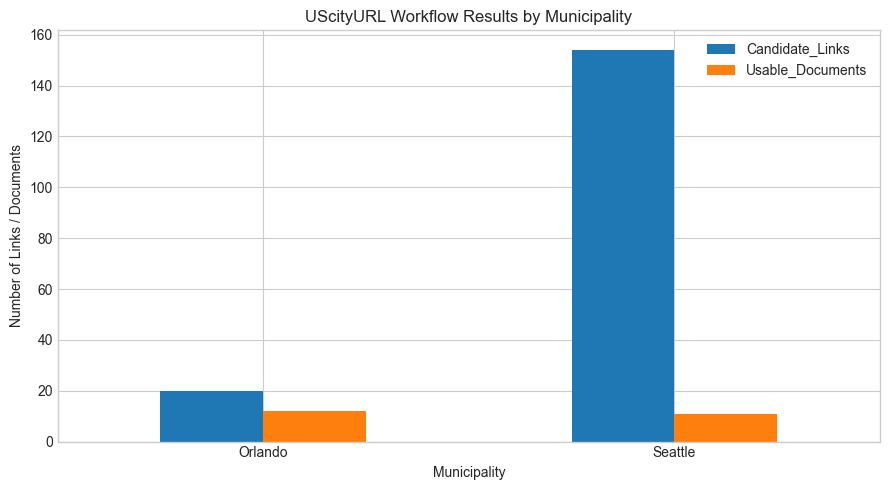

In [23]:
# compare extracted text volume
comparison_df.plot(
    x="Municipality",
    y=[
        "Candidate_Links",
        "Usable_Documents"
    ],
    kind="bar",
    figsize=(9, 5)
)

plt.title("UScityURL Workflow Results by Municipality")
plt.ylabel("Number of Links / Documents")
plt.xlabel("Municipality")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7.3 Compare the amount of usable text

This chart adds the word counts from the usable documents for each city. It describes the size of the collected sample, not the quality or strength of a city's resilience planning.

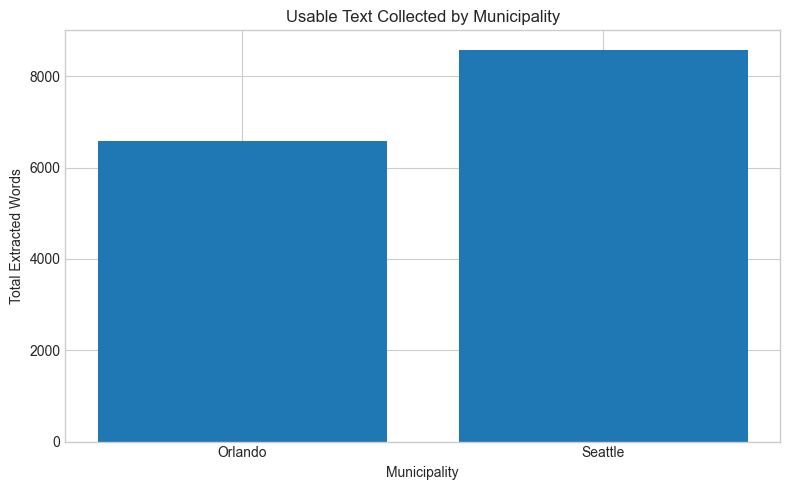

In [24]:
# Topic comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Municipality"],
    comparison_df["Total_Usable_Words"]
)

plt.title("Usable Text Collected by Municipality")
plt.xlabel("Municipality")
plt.ylabel("Total Extracted Words")
plt.tight_layout()
plt.show()


## 7.4 Compare total topic mentions

The code counts the same resilience words in each city's usable documents. Raw totals show what appeared in the sample, but cities with more collected text may naturally have more mentions.

Topic,climate,emergency,flood,heat,housing,hurricane,infrastructure,mitigation,resilience,storm,sustainability
Municipality,,,,,,,,,,,
Orlando,2,19,29,2,29,7,3,5,20,25,1
Seattle,19,22,10,0,18,0,1,3,1,23,2


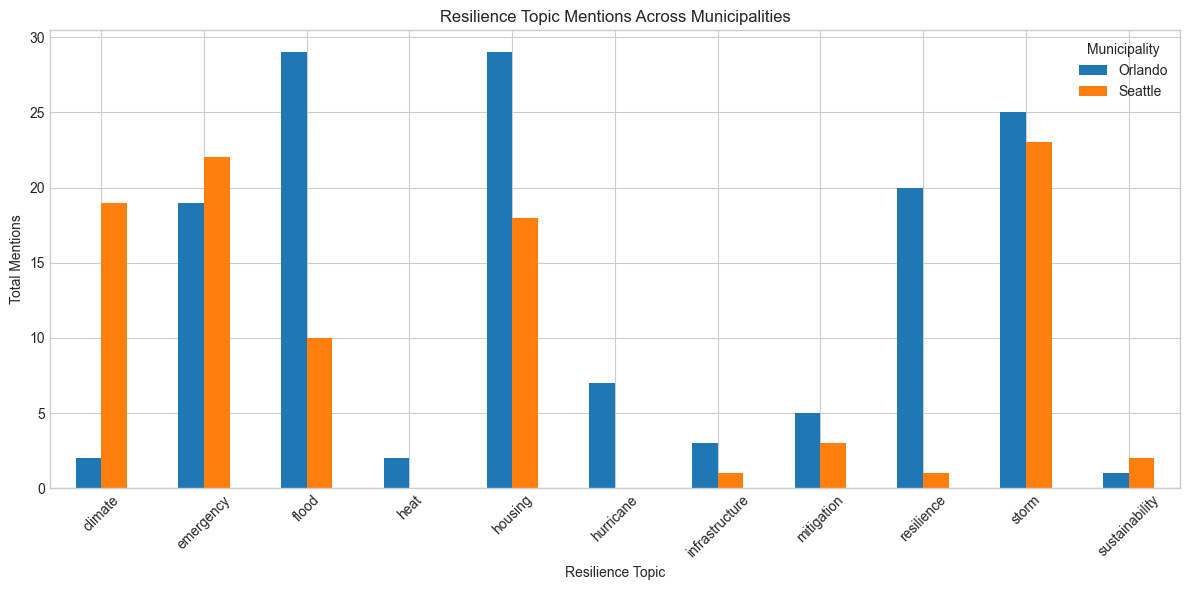

In [25]:

TOPICS = [
    "resilience", "climate", "flood",
    "hurricane", "storm", "heat",
    "housing", "infrastructure",
    "emergency", "mitigation",
    "sustainability"
]

def count_topic(text, topic):
    pattern = rf"(?<!\w){re.escape(topic)}(?!\w)"

    return len(re.findall(
        pattern,
        text or "",
        flags=re.IGNORECASE
    ))

topic_rows = []

if not documents_df.empty:

    usable_documents = documents_df[
        (documents_df["quality"] == "Usable")
        & (~documents_df["exact_duplicate"])
    ].copy()

    for _, document in usable_documents.iterrows():

        for topic in TOPICS:

            count = count_topic(
                document["text"], topic
            )

            topic_rows.append({
                "Municipality": document["municipality"],
                "Topic": topic,
                "Mentions": count,
                "Word_Count": document["word_count"]
            })

topic_df = pd.DataFrame(topic_rows)

if not topic_df.empty:

    topic_summary = topic_df.groupby(
        ["Municipality", "Topic"]
    )["Mentions"].sum().unstack(fill_value=0)

    display(topic_summary)

    topic_summary.T.plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title(
        "Resilience Topic Mentions Across Municipalities"
    )
    plt.ylabel("Total Mentions")
    plt.xlabel("Resilience Topic")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No usable documents available for topic analysis.")


## 7.5 Compare topics after adjusting for text length

Topic counts are converted to mentions per 1,000 words. This gives a fairer text comparison, although the result still describes only the small set of pages collected in this run.

Topic,climate,emergency,flood,heat,housing,hurricane,infrastructure,mitigation,resilience,storm,sustainability
Municipality,,,,,,,,,,,
Orlando,0.30,2.89,4.41,0.3,4.41,1.06,0.46,0.76,3.04,3.80,0.15
Seattle,2.22,2.57,1.17,0.0,2.10,0.00,0.12,0.35,0.12,2.68,0.23


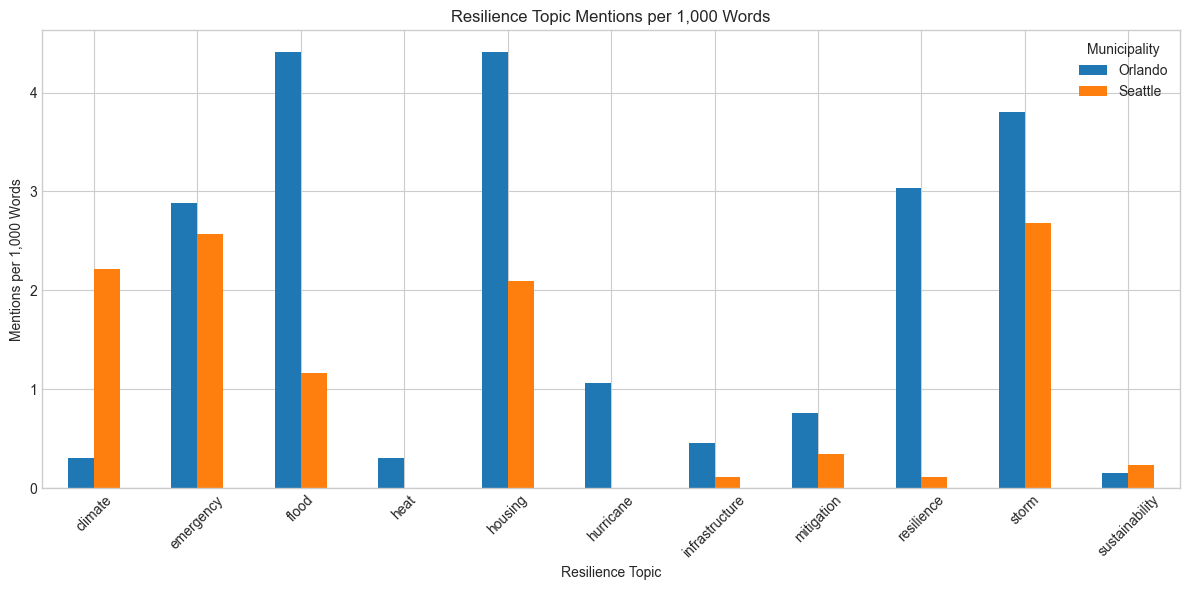

In [26]:
# Total usable words per municipality
word_totals = usable_documents.groupby(
    "municipality"
)["word_count"].sum()

# Normalize topic counts per 1,000 words
normalized_topics = topic_summary.div(
    word_totals, axis=0
) * 1000

display(normalized_topics.round(2))

# Plot normalized frequencies
normalized_topics.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Resilience Topic Mentions per 1,000 Words"
)
plt.xlabel("Resilience Topic")
plt.ylabel("Mentions per 1,000 Words")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()